# Linear Regression from Scratch: OLS & Gradient Descent

## 1. Overview and Intuition
**Linear Regression** is the bedrock supervised learning algorithm for continuous target prediction. It models the relationship between an input vector $x \in \mathbb{R}^D$ and a continuous scalar output $y \in \mathbb{R}$ as a linear combination of features plus a bias (intercept) term.

### Mathematical Formulation
The linear model hypothesis is:
$$\hat{y}(x) = w^T x + b = w_0 + \sum_{j=1}^D w_j x_j$$

By augmenting each sample with a constant dummy feature $x_0 = 1$, the model compactly expresses in matrix form as:
$$\hat{y} = X w, \quad \text{where } X \in \mathbb{R}^{N \times (D+1)}, \; w \in \mathbb{R}^{D+1}$$

### Loss Function (Mean Squared Error / MSE)
The objective is to find parameter vector $w$ that minimizes the sum of squared residuals:
$$\mathcal{J}(w) = \frac{1}{2N} \|X w - y\|^2_2 = \frac{1}{2N} \sum_{i=1}^N (x_i^T w - y_i)^2$$

--- 

### Method 1: Ordinary Least Squares (Closed-Form Normal Equation)
Setting the gradient of $\mathcal{J}(w)$ to zero yields:
$$\nabla_w \mathcal{J}(w) = \frac{1}{N} X^T (X w - y) = 0 \implies X^T X w = X^T y$$
Assuming $X^T X$ is invertible, the analytical optimal solution is:
$$w^* = (X^T X)^{-1} X^T y$$
We can solve this $(D+1) \times (D+1)$ linear system directly using **Gauss-Jordan Elimination** with partial pivoting in $\mathcal{O}(N D^2 + D^3)$.

--- 

### Method 2: Batch Gradient Descent
When $D$ is very large (making matrix inversion computationally expensive), parameters are iteratively updated by descending along the negative gradient of the loss surface:
$$\frac{\partial \mathcal{J}}{\partial w_j} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i) x_{i, j}$$
$$\frac{\partial \mathcal{J}}{\partial b} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i)$$

Parameter update rules for each iteration:
$$w_j \leftarrow w_j - \alpha \frac{\partial \mathcal{J}}{\partial w_j}, \quad b \leftarrow b - \alpha \frac{\partial \mathcal{J}}{\partial b}$$
where $\alpha > 0$ is the learning rate.

## 2. Implementation in Pure Python (Zero Dependencies)

In [2]:
import math
import random
from typing import List, Tuple


# ---------------------------------------------------------------------------
# Linear Algebra Primitives
# ---------------------------------------------------------------------------

def matrix_transpose(matrix: List[List[float]]) -> List[List[float]]:
    """Transposes an (M x N) matrix into an (N x M) matrix."""
    return [list(col) for col in zip(*matrix)]


def matrix_multiply(A: List[List[float]], B: List[List[float]]) -> List[List[float]]:
    """Multiplies matrix A (M x K) by matrix B (K x N)."""
    n_rows_A, n_cols_A = len(A), len(A[0])
    n_rows_B, n_cols_B = len(B), len(B[0])
    if n_cols_A != n_rows_B:
        raise ValueError(f"Incompatible matrix shapes: ({n_rows_A}x{n_cols_A}) and ({n_rows_B}x{n_cols_B})")

    B_transposed = matrix_transpose(B)
    return [
        [sum(a * b for a, b in zip(row_a, col_b)) for col_b in B_transposed]
        for row_a in A
    ]


def solve_linear_system(A: List[List[float]], b: List[float]) -> List[float]:
    """Solves the linear system A x = b using Gauss-Jordan elimination with partial pivoting.

    Args:
        A: Square coefficient matrix of size (N x N).
        b: Right-hand side vector of length N.

    Returns:
        Solution vector x of length N.
    """
    n = len(A)
    # Form augmented matrix [A | b]
    augmented = [row[:] + [b[i]] for i, row in enumerate(A)]

    for i in range(n):
        # Partial pivoting for numerical stability
        max_row = max(range(i, n), key=lambda r: abs(augmented[r][i]))
        if abs(augmented[max_row][i]) < 1e-12:
            raise ValueError("Singular matrix: linear system has no unique solution.")

        # Swap current row with pivot row
        augmented[i], augmented[max_row] = augmented[max_row], augmented[i]

        # Normalize pivot row
        pivot = augmented[i][i]
        for col in range(i, n + 1):
            augmented[i][col] /= pivot

        # Eliminate all other rows
        for r in range(n):
            if r != i:
                factor = augmented[r][i]
                for col in range(i, n + 1):
                    augmented[r][col] -= factor * augmented[i][col]

    return [augmented[r][n] for r in range(n)]


# ---------------------------------------------------------------------------
# Evaluation Metrics
# ---------------------------------------------------------------------------

def mean_squared_error(y_true: List[float], y_pred: List[float]) -> float:
    """Computes Mean Squared Error (MSE)."""
    return sum((yt - yp) ** 2 for yt, yp in zip(y_true, y_pred)) / len(y_true)


def r2_score(y_true: List[float], y_pred: List[float]) -> float:
    """Computes coefficient of determination R^2 score."""
    y_mean = sum(y_true) / len(y_true)
    ss_tot = sum((y - y_mean) ** 2 for y in y_true)
    ss_res = sum((yt - yp) ** 2 for yt, yp in zip(y_true, y_pred))
    return 1.0 - (ss_res / ss_tot) if ss_tot > 0 else 0.0

### 2.1 Model Implementations: OLS and Gradient Descent

In [3]:
class LinearRegressionOLS:
    """Ordinary Least Squares (Closed-form Normal Equation) Linear Regression."""

    def __init__(self) -> None:
        self.weights: List[float] = []
        self.bias: float = 0.0

    def fit(self, X: List[List[float]], y: List[float]) -> "LinearRegressionOLS":
        """Fits weights and bias using the Normal Equation (X^T X) w = X^T y."""
        # Prepend column of ones for the bias term: X_aug = [1, x_1, ..., x_D]
        X_aug = [[1.0] + list(sample) for sample in X]
        X_T = matrix_transpose(X_aug)

        # Normal equation components
        XtX = matrix_multiply(X_T, X_aug)
        # X^T * y
        Xty = [sum(row[i] * y[i] for i in range(len(y))) for row in X_T]

        # Solve (X^T X) w = X^T y
        solution = solve_linear_system(XtX, Xty)
        self.bias = solution[0]
        self.weights = solution[1:]
        return self

    def predict(self, X: List[List[float]]) -> List[float]:
        """Predicts continuous target values for given feature vectors."""
        return [
            sum(w * x for w, x in zip(self.weights, sample)) + self.bias
            for sample in X
        ]


class LinearRegressionGD:
    """Batch Gradient Descent Linear Regression."""

    def __init__(self, learning_rate: float = 0.05, epochs: int = 500) -> None:
        self.lr = learning_rate
        self.epochs = epochs
        self.weights: List[float] = []
        self.bias: float = 0.0

    def fit(self, X: List[List[float]], y: List[float]) -> List[float]:
        """Iteratively updates weights and bias using gradient descent."""
        n_samples = len(X)
        n_features = len(X[0])

        # Initialize weights and bias to zeros
        self.weights = [0.0] * n_features
        self.bias = 0.0
        loss_history: List[float] = []

        for _ in range(self.epochs):
            # Compute predictions
            y_pred = [
                sum(w * x for w, x in zip(self.weights, sample)) + self.bias
                for sample in X
            ]

            # Compute current MSE loss
            current_loss = mean_squared_error(y, y_pred)
            loss_history.append(current_loss)

            # Compute gradients: error = y_pred - y
            errors = [yp - yt for yp, yt in zip(y_pred, y)]

            dw = [
                sum(errors[i] * X[i][j] for i in range(n_samples)) / n_samples
                for j in range(n_features)
            ]
            db = sum(errors) / n_samples

            # Parameter updates
            self.weights = [w - self.lr * grad for w, grad in zip(self.weights, dw)]
            self.bias -= self.lr * db

        return loss_history

    def predict(self, X: List[List[float]]) -> List[float]:
        """Predicts continuous target values for given feature vectors."""
        return [
            sum(w * x for w, x in zip(self.weights, sample)) + self.bias
            for sample in X
        ]

## 3. Demonstration & Verification on Synthetic Data

We generate synthetic data following the ground-truth equation:
$$y = 3.5 \cdot x + 4.2 + \epsilon, \quad \epsilon \sim \mathcal{N}(0, 1.2)$$

In [4]:
random.seed(42)
TRUE_W = 3.5
TRUE_B = 4.2
N_SAMPLES = 60

# Generate 1D data with Gaussian noise
X_train = [[random.uniform(0.0, 10.0)] for _ in range(N_SAMPLES)]
y_train = [TRUE_W * x[0] + TRUE_B + random.gauss(0.0, 1.2) for x in X_train]

# 1. Fit OLS model
ols_model = LinearRegressionOLS().fit(X_train, y_train)
ols_preds = ols_model.predict(X_train)
ols_mse = mean_squared_error(y_train, ols_preds)
ols_r2 = r2_score(y_train, ols_preds)

# 2. Fit Gradient Descent model
gd_model = LinearRegressionGD(learning_rate=0.02, epochs=600)
loss_curve = gd_model.fit(X_train, y_train)
gd_preds = gd_model.predict(X_train)
gd_mse = mean_squared_error(y_train, gd_preds)
gd_r2 = r2_score(y_train, gd_preds)

print("=== Model Comparison ===")
print(f"Ground Truth:      y = {TRUE_W:.2f} * x + {TRUE_B:.2f}")
print(f"OLS Solution:      y = {ols_model.weights[0]:.4f} * x + {ols_model.bias:.4f} | MSE: {ols_mse:.4f} | R^2: {ols_r2:.4f}")
print(f"Gradient Descent:  y = {gd_model.weights[0]:.4f} * x + {gd_model.bias:.4f} | MSE: {gd_mse:.4f} | R^2: {gd_r2:.4f}")

=== Model Comparison ===
Ground Truth:      y = 3.50 * x + 4.20
OLS Solution:      y = 3.5174 * x + 4.2483 | MSE: 1.2986 | R^2: 0.9872
Gradient Descent:  y = 3.5377 * x + 4.1221 | MSE: 1.3031 | R^2: 0.9872


## 4. Visualizing Regression Line and Loss Convergence with Matplotlib

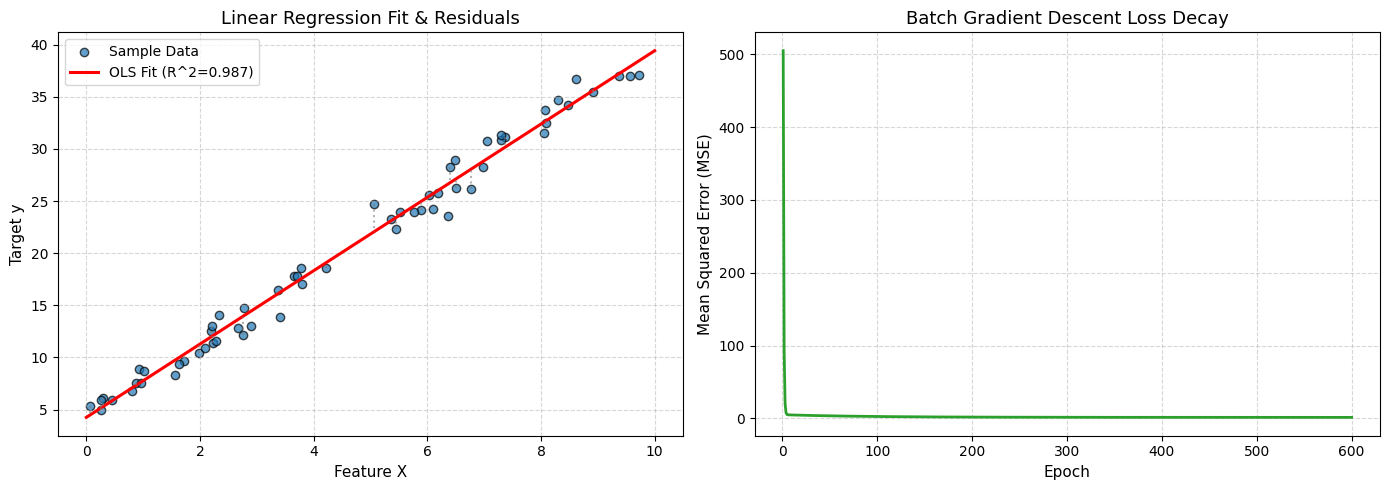

In [5]:
try:
    import matplotlib.pyplot as plt

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Regression Fit and Residual Errors
    xs = [x[0] for x in X_train]
    ax1.scatter(xs, y_train, color="#1f77b4", alpha=0.7, edgecolors="k", label="Sample Data")

    # Regression line
    x_line = [0.0, 10.0]
    y_line_ols = [ols_model.weights[0] * x + ols_model.bias for x in x_line]
    ax1.plot(x_line, y_line_ols, color="red", linewidth=2.2, label=f"OLS Fit (R^2={ols_r2:.3f})")

    # Residual lines (vertical distance from points to regression line)
    for x_val, y_val, y_hat in zip(xs[:20], y_train[:20], ols_preds[:20]):
        ax1.plot([x_val, x_val], [y_val, y_hat], color="gray", linestyle=":", alpha=0.6)

    ax1.set_title("Linear Regression Fit & Residuals", fontsize=13)
    ax1.set_xlabel("Feature X", fontsize=11)
    ax1.set_ylabel("Target y", fontsize=11)
    ax1.legend()
    ax1.grid(True, linestyle="--", alpha=0.5)

    # 2. Gradient Descent MSE Convergence
    ax2.plot(range(1, len(loss_curve) + 1), loss_curve, color="#2ca02c", linewidth=2)
    ax2.set_title("Batch Gradient Descent Loss Decay", fontsize=13)
    ax2.set_xlabel("Epoch", fontsize=11)
    ax2.set_ylabel("Mean Squared Error (MSE)", fontsize=11)
    ax2.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib is not installed in the environment. Skipping visual plot.")